Prediction: No


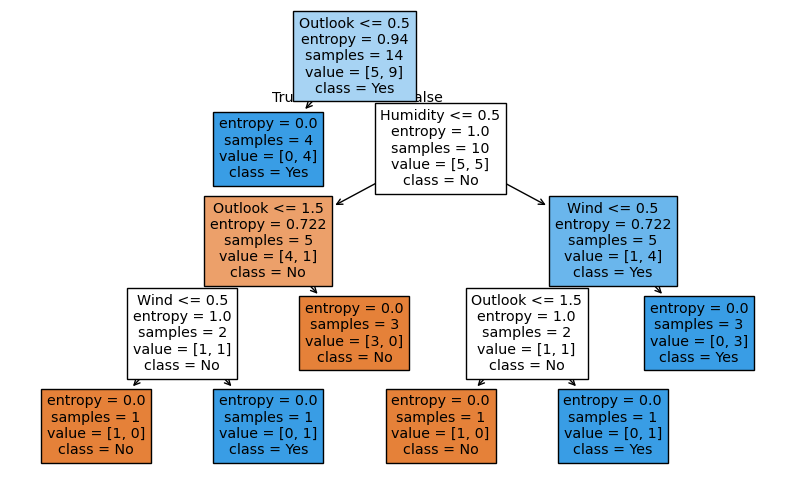

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

data = [
    ['Sunny', 'Hot', 'High', 'Weak', 'No'],
    ['Sunny', 'Hot', 'High', 'Strong', 'No'],
    ['Overcast', 'Hot', 'High', 'Weak', 'Yes'],
    ['Rain', 'Mild', 'High', 'Weak', 'Yes'],
    ['Rain', 'Cool', 'Normal', 'Weak', 'Yes'],
    ['Rain', 'Cool', 'Normal', 'Strong', 'No'],
    ['Overcast', 'Cool', 'Normal', 'Strong', 'Yes'],
    ['Sunny', 'Mild', 'High', 'Weak', 'No'],
    ['Sunny', 'Cool', 'Normal', 'Weak', 'Yes'],
    ['Rain', 'Mild', 'Normal', 'Weak', 'Yes'],
    ['Sunny', 'Mild', 'Normal', 'Strong', 'Yes'],
    ['Overcast', 'Mild', 'High', 'Strong', 'Yes'],
    ['Overcast', 'Hot', 'Normal', 'Weak', 'Yes'],
    ['Rain', 'Mild', 'High', 'Strong', 'No']
]

# Split features and labels
X = []
y = []
for row in data:
    X.append(row[:-1])
    y.append(row[-1])

# Encode categorical features
X_encoded = []
encoders = []
for col in range(4):
    le = LabelEncoder()
    values = [row[col] for row in X]
    X_encoded.append(le.fit_transform(values))
    encoders.append(le)

X_encoded = list(zip(*X_encoded))

# Train Decision Tree model
feature_names = ['Outlook', 'Temperature', 'Humidity', 'Wind']
model = DecisionTreeClassifier(criterion='entropy')
model.fit(X_encoded, y)

# Make a prediction for a single sample
sample = [['Sunny', 'Cool', 'High', 'Strong']]
encoded_sample = []
for i in range(4):
    le = encoders[i]
    encoded_sample.append(le.transform([sample[0][i]])[0])

prediction = model.predict([encoded_sample])
print("Prediction:", prediction[0])

# Plot the Tree
plt.figure(figsize=(10, 6))
plot_tree(model, feature_names=feature_names, class_names=model.classes_, filled=True)
plt.show()